# S02 — Préparation à l'échelle : *silver* puis *gold*

```
bronze/yellow_trips ──nettoyage──► silver/yellow_trips ──agrégats + météo──► gold/...  ──► PostgreSQL
```

- **silver** = données propres, typées, une ligne par course
- **gold** = tables prêtes pour les dashboards (une question métier = une table)

In [1]:
import sys; sys.path.append("/home/jovyan/work")
from pyspark.sql import functions as F
from commun.spark_utils import creer_session, RAW, LAKE

from commun.spark_utils import format_tables, vers_postgres
spark = creer_session("S02")
FMT = format_tables(spark)
bronze = spark.read.format(FMT).load(f"{LAKE}/bronze/yellow_trips")
print(f"bronze : {bronze.count():,} lignes")

Préparation de Spark 4.2.0 (Hadoop 3.5.0) + Delta Lake + data lake S3 … le premier démarrage peut prendre quelques minutes.
Session prête. Spark UI : http://localhost:4040
bronze : 3,475,226 lignes


## 1. Règles de nettoyage

Chaque règle est nommée et comptée : on doit pouvoir **justifier** chaque ligne retirée.

In [2]:
MOIS = "2025-01"
import datetime as dt
a, m = map(int, MOIS.split("-"))
debut, fin = f"{MOIS}-01", dt.date(a + (m == 12), m % 12 + 1, 1).isoformat()

regles = {
    "montant_negatif_ou_nul": F.col("total_amount") <= 0,
    "passagers_0_ou_vide":    (F.col("passenger_count") == 0) | F.col("passenger_count").isNull(),
    "distance_aberrante":     (F.col("trip_distance") <= 0) | (F.col("trip_distance") > 100),
    "hors_du_mois":           (F.col("tpep_pickup_datetime") < F.lit(debut)) | (F.col("tpep_pickup_datetime") >= F.lit(fin)),
    "duree_aberrante":        (F.col("tpep_dropoff_datetime") <= F.col("tpep_pickup_datetime")),
    
    # Correction : on vérifie que la durée est > 0 avant de diviser
    "vitesse_aberrante":      F.when(
                                  (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) > 0,
                                  F.col("trip_distance") / ((F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 3600) > 80
                              ).otherwise(False)
}

"Nouvelle règle vitesse_aberrante ajoutée : une vitesse moyenne de plus de 80 mph en plein New York est irréaliste. Cela permet de supprimer les erreurs matérielles des compteurs que les filtres de distance et de durée, pris séparément, n'auraient pas repérées

In [3]:
from functools import reduce
a_exclure = reduce(lambda x, y: x | y, regles.values())

silver = (bronze
          .filter(~a_exclure)
          .withColumn("duree_min", (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60)
          .withColumn("heure_pickup", F.date_trunc("hour", "tpep_pickup_datetime"))
          .drop("_source", "_ingere_le"))

silver.write.format(FMT).mode("overwrite").save(f"{LAKE}/silver/yellow_trips")
n_s = spark.read.format(FMT).load(f"{LAKE}/silver/yellow_trips").count()
print(f"silver : {n_s:,} lignes ({n_s / bronze.count():.1%} du bronze conservé)")

silver : 2,815,300 lignes (81.0% du bronze conservé)


## 2. Tables *gold*

Une table par usage. On joint les zones (noms lisibles) et la météo (par heure).

In [4]:
silver = spark.read.format(FMT).load(f"{LAKE}/silver/yellow_trips")
zones  = spark.read.format(FMT).load(f"{LAKE}/bronze/zones")
meteo  = spark.read.format(FMT).load(f"{LAKE}/bronze/meteo")

z = zones.select(F.col("LocationID").alias("PULocationID"),
                 F.col("Borough").alias("arrondissement"), F.col("Zone").alias("zone"))

# gold 1 : activité par heure et par arrondissement, avec la météo
gold_horaire = (silver.join(z, "PULocationID", "left")
    .groupBy("heure_pickup", "arrondissement")
    .agg(F.count("*").alias("courses"),
         F.round(F.sum("total_amount"), 2).alias("revenu"),
         F.round(F.avg("total_amount"), 2).alias("prix_moyen"),
         F.round(F.avg("tip_amount"), 2).alias("pourboire_moyen"),
         F.round(F.avg("trip_distance"), 2).alias("distance_moyenne"))
    .join(meteo.withColumnRenamed("horodatage", "heure_pickup"), "heure_pickup", "left"))

# gold 2 : synthèse par zone de départ (pour les cartes)
gold_zones = (silver.join(z, "PULocationID", "left")
    .groupBy("PULocationID", "arrondissement", "zone")
    .agg(F.count("*").alias("courses"),
         F.round(F.avg("total_amount"), 2).alias("prix_moyen"),
         F.round(F.avg(F.col("tip_amount") / F.col("total_amount")), 3).alias("taux_pourboire")))

for nom, df in {"trajets_horaires": gold_horaire, "zones": gold_zones}.items():
    df.write.format(FMT).mode("overwrite").save(f"{LAKE}/gold/{nom}")
    print(f"gold/{nom} : {df.count():,} lignes")

gold/trajets_horaires : 4,033 lignes
gold/zones : 250 lignes


## 3. Exposer le *gold* dans PostgreSQL

Superset, Grafana et Streamlit liront ces tables.

In [5]:
vers_postgres(spark.read.format(FMT).load(f"{LAKE}/gold/trajets_horaires"), "gold_trajets_horaires")
vers_postgres(spark.read.format(FMT).load(f"{LAKE}/gold/zones"), "gold_zones")

Table PostgreSQL « gold_trajets_horaires » écrite.
Table PostgreSQL « gold_zones » écrite.


### Relire les tables depuis PostgreSQL

Les tables *gold* sont maintenant dans la base de restitution. On les relit avec pandas, comme le feront les outils de visualisation.

Pour les parcourir à la souris : http://localhost:8080 (Adminer — système *PostgreSQL*, serveur `postgres`, `cours` / `cours`, base `nyctaxi`).

,table_name
0,gold_trajets_horaires
1,gold_zones


gold_trajets_horaires : 4,033 lignes · gold_zones : 250 lignes


,heure_pickup,arrondissement,courses,revenu,prix_moyen,pourboire_moyen,distance_moyenne,temperature_c,precipitation_mm
0,2025-01-01 15:00:00+00:00,Brooklyn,10,289.12,28.91,1.33,4.24,8.1,0.0
1,2025-01-02 01:00:00+00:00,N/A,2,233.00,116.50,0.50,0.08,4.6,0.0
2,2025-01-04 03:00:00+00:00,Manhattan,4335,96907.22,22.35,2.95,2.25,-1.3,0.0
3,2025-01-07 14:00:00+00:00,Unknown,9,258.06,28.67,3.94,3.22,-6.0,0.0
4,2025-01-11 13:00:00+00:00,Bronx,10,372.72,37.27,0.00,9.19,-2.9,0.1


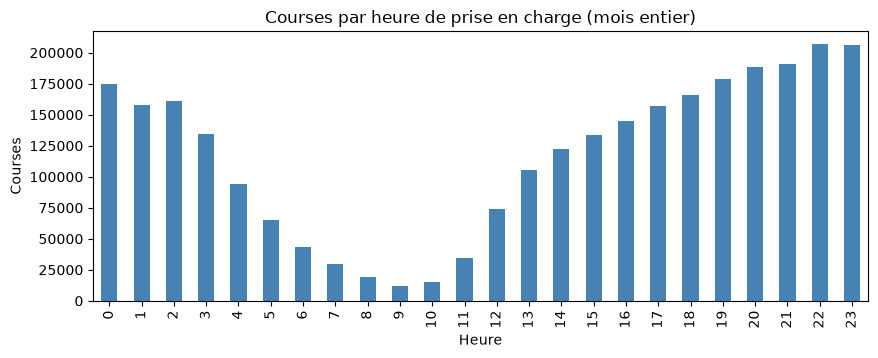

In [6]:
from commun.donnees import lire
import matplotlib.pyplot as plt

# 1. Les tables présentes dans la base
display(lire("SELECT table_name FROM information_schema.tables WHERE table_schema = 'public'"))

# 2. Un aperçu de chaque table gold
horaires = lire("gold_trajets_horaires")
zones = lire("gold_zones")
print(f"gold_trajets_horaires : {len(horaires):,} lignes · gold_zones : {len(zones):,} lignes")
display(horaires.head())

# 3. Un premier graphique, directement depuis PostgreSQL
par_heure = lire("""
    SELECT EXTRACT(HOUR FROM heure_pickup)::int AS heure, SUM(courses) AS courses
    FROM gold_trajets_horaires
    GROUP BY 1 ORDER BY 1
""")
ax = par_heure.plot.bar(x="heure", y="courses", legend=False, color="steelblue", figsize=(10, 3.5))
ax.set(title="Courses par heure de prise en charge (mois entier)", xlabel="Heure", ylabel="Courses")
plt.show()

## 4. Premiers graphiques exploratoires (sur le *gold*, donc petits)

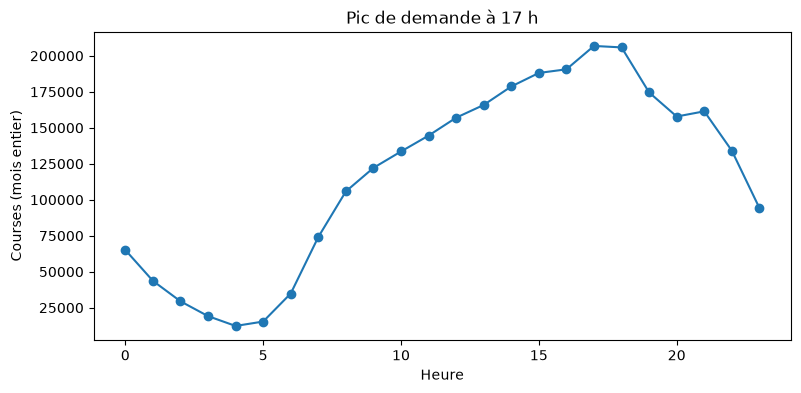

In [7]:
import matplotlib.pyplot as plt
h = (spark.read.format(FMT).load(f"{LAKE}/gold/trajets_horaires")
          .groupBy(F.hour("heure_pickup").alias("heure"))
          .agg(F.sum("courses").alias("courses"))
          .orderBy("heure").toPandas())
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(h["heure"], h["courses"], marker="o")
ax.set_xlabel("Heure"); ax.set_ylabel("Courses (mois entier)")
ax.set_title(f"Pic de demande à {int(h.loc[h['courses'].idxmax(), 'heure'])} h")
plt.show()

In [8]:
p = (spark.read.format(FMT).load(f"{LAKE}/gold/trajets_horaires")
          .withColumn("pluie", F.when(F.col("precipitation_mm") > 0, "pluie").otherwise("sec"))
          .groupBy("pluie").agg(F.avg("courses").alias("courses_par_heure_et_arrondissement"))
          .toPandas())
p

,pluie,courses_par_heure_et_arrondissement
0,pluie,787.303207
1,sec,689.771003


## C'est réussi quand…
- `silver` et `gold` sont visibles dans la console RustFS ;
- `SELECT * FROM gold_trajets_horaires LIMIT 10;` répond dans PostgreSQL ;
- vous savez justifier chaque règle de nettoyage et le nombre de lignes retirées.

**Exercice :** ajoutez une table *gold* « aéroports » (zones JFK, LaGuardia, Newark) : courses, prix moyen, durée moyenne par heure.

In [9]:
# Filtrer les zones correspondant aux aéroports
aeroports_zones = z.filter(F.col("zone").rlike("(?i)JFK|LaGuardia|Newark"))

# gold 3 : synthèse aéroports par heure
gold_aeroports = (silver.join(aeroports_zones, "PULocationID", "inner")
    .groupBy("heure_pickup", "zone")
    .agg(
         F.count("*").alias("courses"),
         F.round(F.avg("total_amount"), 2).alias("prix_moyen"),
         F.round(F.avg("duree_min"), 2).alias("duree_moyenne")
    )
    .orderBy("heure_pickup", "zone"))

# Sauvegarder la nouvelle table gold
gold_aeroports.write.format(FMT).mode("overwrite").save(f"{LAKE}/gold/aeroports")
print(f"gold/aeroports : {gold_aeroports.count():,} lignes")

gold/aeroports : 1,487 lignes


Une course de 0,1 mile à 80 $ : erreur à supprimer ou cas réel à garder ?

C'est un cas réel à garder.

Il ne faut pas supprimer cette ligne car ce n'est pas nécessairement une erreur de capteur. Cela s'explique par les règles tarifaires des taxis new-yorkais :

Forfait aéroport (Flat Fare) : Les trajets vers ou depuis l'aéroport JFK ont un prix fixe (qui, avec les péages et les pourboires, atteint facilement 80 $). Si le chauffeur oublie d'activer son compteur au départ et ne l'allume qu'à l'arrivée pour la facturation, la distance enregistrée sera quasi nulle (0,1 mile) mais le prix facturé sera le bon.

Tarif négocié : Pour certains trajets spécifiques, le chauffeur et le client conviennent d'un prix à l'avance (tarif négocié), indépendamment de la distance parcourue.

Conclusion : Au lieu de supprimer aveuglément cette ligne via un filtre de distance, la bonne pratique est de croiser cette donnée avec la colonne RatecodeID. Si le code tarifaire indique "JFK" (2) ou "Tarif négocié" (5), alors la course est parfaitement valide.

In [13]:
spark.stop()